In [3]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\SPR')
import Treat_SPR_func as Treat_SPR_func
importlib.reload(Treat_SPR_func)
from Treat_SPR_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [4]:
path_simu = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND - dimeres\SPR'

simu_shape = 'cylinder'
diameter = 'D_200'
#diameter = 'Single ND'
sample_name = 'Silice thick'

dir_root = '\\'.join((path_simu, sample_name, diameter))

Fname_list = ['D_200_polar_0_PML_500nm_tPML_200_nm - spectra gap sweep part 2']
# Fname_list = ['D_200_polar_0_PML_500nm_tPML_200_nm - polar ortho - spectra gap sweep']
# Fname_list = ['D_200_polar_0_PML_500nm_tPML_200_nm - polar ortho - spectra gap sweep - part 2']
# Fname_list = ['e_40nm_Dmin_80nm_Dmax_240nm - spectra']




#fname_raw = 'Sapphire - raw simu results'


Spectra_data = get_raw_size_sweep_data_Nathan(dir_root, Fname_list)

fit_Lorentz_all_data(Spectra_data, w_guess=0.1)

#dir_to_save = dir_root + '\Treated_SPR'


#fname = 'Treated_simulations'
#save_treated_simulation_data(Spectra_data, dir_to_save, fname)

Total size of raw data : 246
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------
----------- Find spectra size -----------


 res fit : [np.float64(1.2417274530006672), np.float64(0.666775401865864), np.float64(301991.2923664551)]
 res fit : [np.float64(1.397959979362739), np.float64(0.6517543357532691), np.float64(281222.39856624836)]
 res fit : [np.float64(1.4574911784428257), np.float64(0.59338701507604), np.float64(269253.3577395815)]
 res fit : [np.float64(1.4835300291352096), np.float64(0.5299710288289188), np.float64(257655.72907949283)]
 res fit : [np.float64(1.4934641354175129), np.float64(0.4772346023367021), np.float64(248094.77145586326)]
 res fit : [np.float64(1.4917149907598564), np.float64(0.42403524664882325), np.float64(234246.29552258176)]


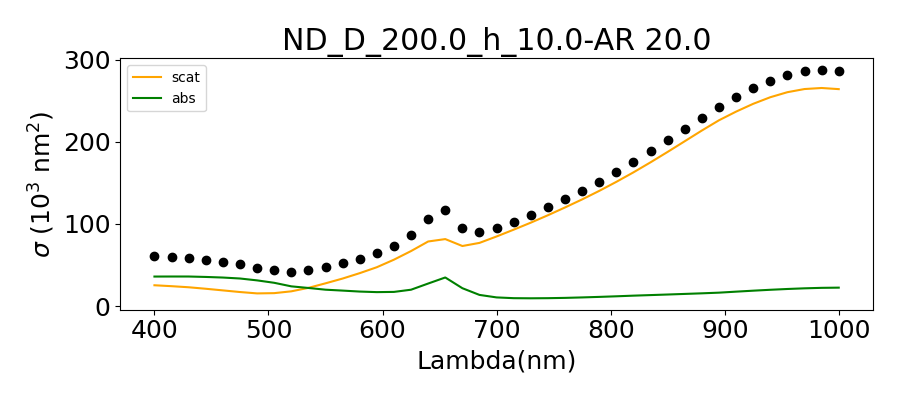

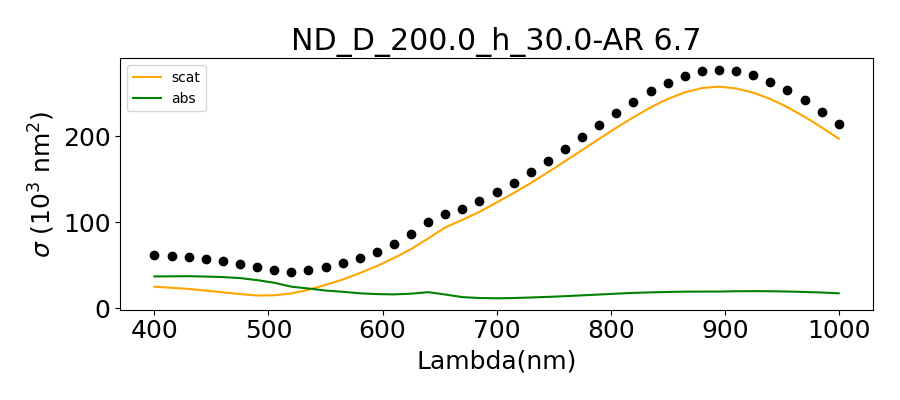

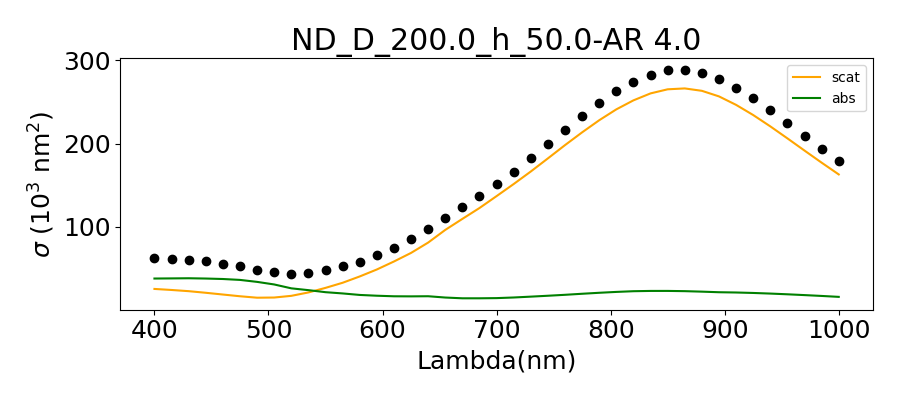

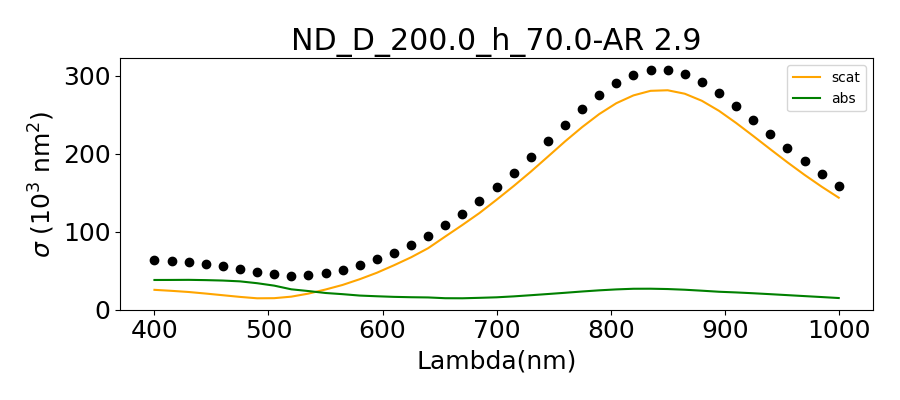

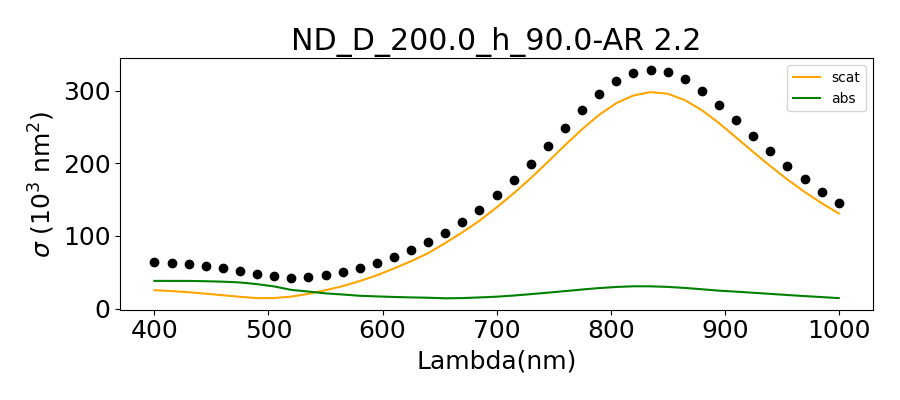

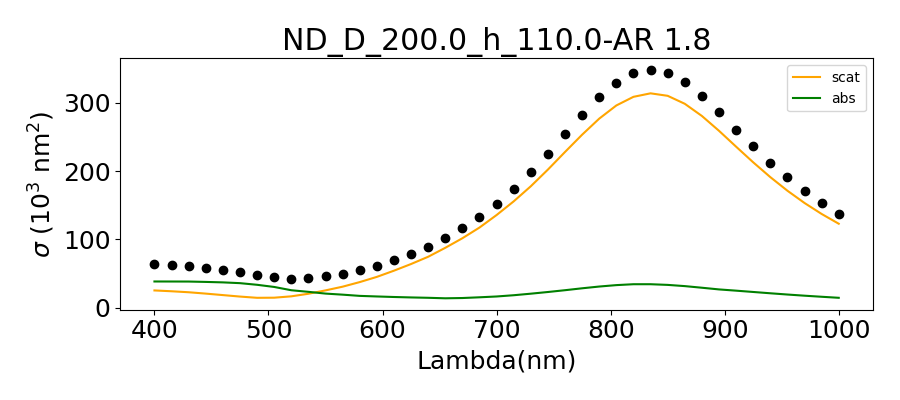

In [5]:
Lambda = np.linspace(400, 1000, 1000)
E = 1240/Lambda

if 1 :
        
    for key in Spectra_data :
        
        spectra = Spectra_data[key]

        
            
        fig, ax = plt.subplots(figsize = (9,4))

        ax.scatter(spectra['Lambda'], spectra['Sigma_ext']*1e-3, color='black')
        ax.plot(spectra['Lambda'], spectra['Sigma_scat']*1e-3, color='orange', label='scat')
        ax.plot(spectra['Lambda'], spectra['Sigma_abs']*1e-3, color='green', label='abs')




        #ax.plot(1240/E, Lorentz_no_offset(E, *spectra['res_fit']['coeffs'])*1e-3)
        #ax.scatter(spectra['Lambda'][spectra['res_fit']['idx']], spectra['Sigma_ext'][spectra['res_fit']['idx']]*1e-3, color='red')


        print(' res fit : {}'.format([*spectra['res_fit']['coeffs']]))

        ax.set_title(key + '-' + 'AR '+ str(spectra['AR']))
        ax.set_xlabel('Lambda(nm)')
        ax.set_ylabel(r'$\sigma$ ($10^3$ nm$^2$)')
        plt.legend(fontsize=10)
        plt.tight_layout()